In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

from torch.utils.data import DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

transform = transforms.ToTensor()

train_dataset = torchvision.datasets.MNIST(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.MNIST(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))

Using device: cpu


100%|██████████| 9.91M/9.91M [00:00<00:00, 12.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 342kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.33MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.5MB/s]

Training samples: 60000
Testing samples: 10000


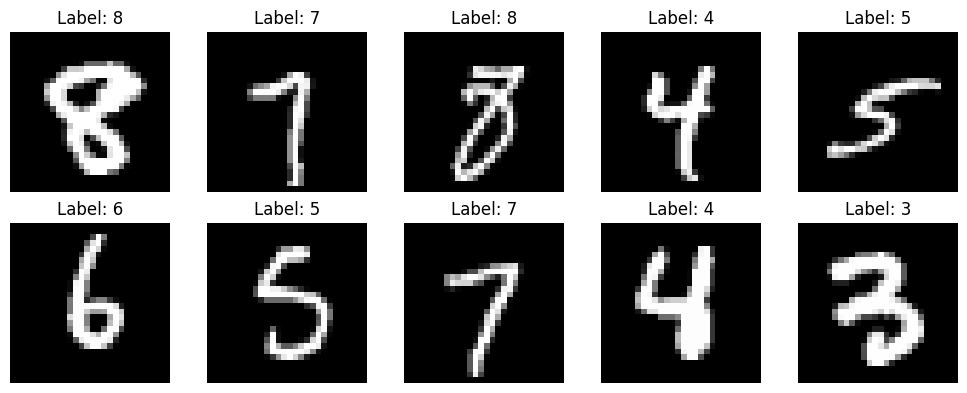

Image shape: torch.Size([128, 1, 28, 28])
Pixel range: 0.0 1.0


In [ ]:
images, labels = next(iter(train_loader))

plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(images[i].squeeze(), cmap='gray')
    plt.title(f"Label: {labels[i].item()}")
    plt.axis('off')

plt.tight_layout()
plt.show()

print("Image shape:", images.shape)
print("Pixel range:", images.min().item(), images.max().item())

In [ ]:
class VAE(nn.Module):
    def __init__(self, latent_dim=20):
        super(VAE, self).__init__()

        self.encoder = nn.Sequential(
            nn.Linear(784, 400),
            nn.ReLU()
        )

        self.fc_mu = nn.Linear(400, latent_dim)
        self.fc_logvar = nn.Linear(400, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 400),
            nn.ReLU(),
            nn.Linear(400, 784),
            nn.Sigmoid()
        )

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x):
        x = x.view(-1, 784)

        hidden = self.encoder(x)

        mu = self.fc_mu(hidden)
        logvar = self.fc_logvar(hidden)

        z = self.reparameterize(mu, logvar)

        reconstructed = self.decoder(z)

        return reconstructed, mu, logvar


model = VAE(latent_dim=20).to(device)

print(model)

VAE(
  (encoder): Sequential(
    (0): Linear(in_features=784, out_features=400, bias=True)
    (1): ReLU()
  )
  (fc_mu): Linear(in_features=400, out_features=20, bias=True)
  (fc_logvar): Linear(in_features=400, out_features=20, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=20, out_features=400, bias=True)
    (1): ReLU()
    (2): Linear(in_features=400, out_features=784, bias=True)
    (3): Sigmoid()
  )
)


In [ ]:
optimizer = optim.Adam(model.parameters(), lr=0.001)

def vae_loss(reconstructed, original, mu, logvar):
    reconstruction_loss = nn.functional.binary_cross_entropy(
        reconstructed,
        original.view(-1, 784),
        reduction='sum'
    )

    kl_loss = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    )

    return reconstruction_loss + kl_loss


epochs = 15
train_losses = []

for epoch in range(epochs):
    model.train()
    total_loss = 0

    for images, _ in train_loader:
        images = images.to(device)

        optimizer.zero_grad()

        reconstructed, mu, logvar = model(images)

        loss = vae_loss(reconstructed, images, mu, logvar)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_dataset)
    train_losses.append(average_loss)

    print(f"Epoch [{epoch+1}/{epochs}], Loss: {average_loss:.4f}")

print("Training completed!")

Epoch [1/15], Loss: 163.7155
Epoch [2/15], Loss: 121.8525
Epoch [3/15], Loss: 114.6186
Epoch [4/15], Loss: 111.6177
Epoch [5/15], Loss: 109.8438
Epoch [6/15], Loss: 108.7419
Epoch [7/15], Loss: 107.8933
Epoch [8/15], Loss: 107.2533
Epoch [9/15], Loss: 106.6952
Epoch [10/15], Loss: 106.2995
Epoch [11/15], Loss: 105.9042
Epoch [12/15], Loss: 105.6009
Epoch [13/15], Loss: 105.3313
Epoch [14/15], Loss: 105.0992


In [ ]:
model.eval()

total_test_loss = 0

with torch.no_grad():
    for images, _ in test_loader:
        images = images.to(device)

        reconstructed, mu, logvar = model(images)

        loss = vae_loss(reconstructed, images, mu, logvar)

        total_test_loss += loss.item()

print("Test Loss:", total_test_loss / len(test_dataset))


images, _ = next(iter(test_loader))
images = images[:10].to(device)

with torch.no_grad():
    reconstructed, _, _ = model(images)

plt.figure(figsize=(12, 4))

for i in range(10):
    plt.subplot(2, 10, i + 1)
    plt.imshow(images[i].cpu().squeeze(), cmap='gray')
    plt.axis('off')

    plt.subplot(2, 10, i + 11)
    plt.imshow(reconstructed[i].cpu().view(28, 28), cmap='gray')
    plt.axis('off')

plt.suptitle("Original Images vs Reconstructed Images")
plt.show()


plt.figure(figsize=(8, 4))
plt.plot(train_losses)
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("VAE Training Loss Curve")
plt.grid()
plt.show()

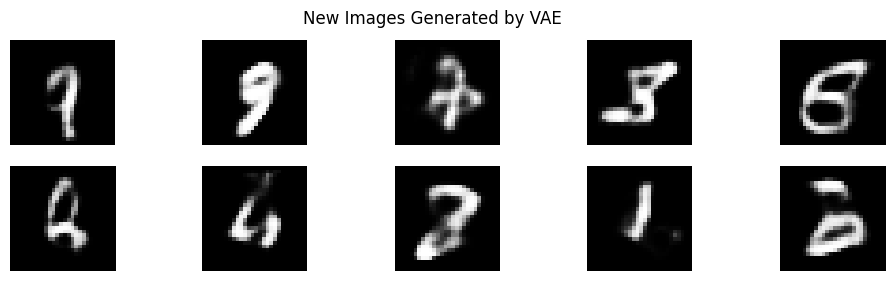

AE Epoch [1/15], Loss: 129.3096
AE Epoch [2/15], Loss: 82.3506
AE Epoch [3/15], Loss: 76.6542
AE Epoch [4/15], Loss: 74.0039
AE Epoch [5/15], Loss: 72.2567
AE Epoch [6/15], Loss: 71.0499
AE Epoch [7/15], Loss: 70.0701
AE Epoch [8/15], Loss: 69.3092
AE Epoch [9/15], Loss: 68.6632
AE Epoch [10/15], Loss: 68.1578
AE Epoch [11/15], Loss: 67.6968
AE Epoch [12/15], Loss: 67.2999
AE Epoch [13/15], Loss: 66.9746
AE Epoch [14/15], Loss: 66.6614
AE Epoch [15/15], Loss: 66.3830


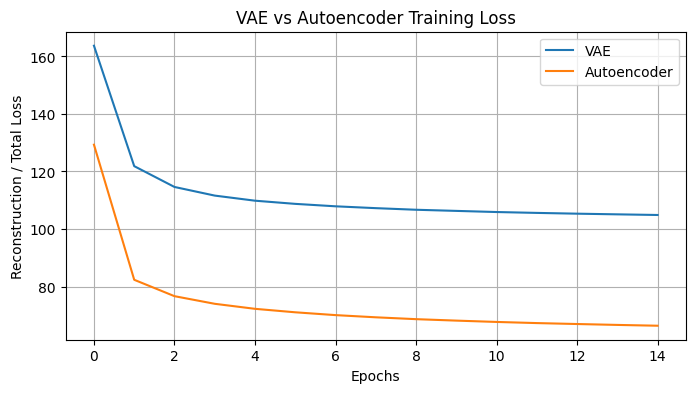

Comparison Summary
VAE: Learns a probabilistic latent space and generates new images.
AE: Learns compressed representations and reconstructs input images.


In [ ]:
# Generate new images using trained VAE

model.eval()

with torch.no_grad():
    z = torch.randn(10, 20).to(device)
    generated_images = model.decoder(z)

plt.figure(figsize=(12, 3))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(generated_images[i].cpu().view(28, 28), cmap='gray')
    plt.axis('off')

plt.suptitle("New Images Generated by VAE")
plt.show()


# Baseline Autoencoder

class Autoencoder(nn.Module):
    def __init__(self):
        super(Autoencoder, self).__init__()

        self.encoder = nn.Sequential(
            nn.Linear(784, 400),
            nn.ReLU(),
            nn.Linear(400, 20)
        )

        self.decoder = nn.Sequential(
            nn.Linear(20, 400),
            nn.ReLU(),
            nn.Linear(400, 784),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = x.view(-1, 784)
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded


ae_model = Autoencoder().to(device)

ae_optimizer = optim.Adam(ae_model.parameters(), lr=0.001)

ae_losses = []

for epoch in range(15):
    ae_model.train()
    total_loss = 0

    for images, _ in train_loader:
        images = images.to(device)

        ae_optimizer.zero_grad()

        output = ae_model(images)

        loss = nn.functional.binary_cross_entropy(
            output,
            images.view(-1, 784),
            reduction='sum'
        )

        loss.backward()
        ae_optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(train_dataset)
    ae_losses.append(avg_loss)

    print(f"AE Epoch [{epoch+1}/15], Loss: {avg_loss:.4f}")


# Compare training loss

plt.figure(figsize=(8, 4))

plt.plot(train_losses, label="VAE")
plt.plot(ae_losses, label="Autoencoder")

plt.xlabel("Epochs")
plt.ylabel("Reconstruction / Total Loss")
plt.title("VAE vs Autoencoder Training Loss")
plt.legend()
plt.grid()
plt.show()


print("Comparison Summary")
print("VAE: Learns a probabilistic latent space and generates new images.")
print("AE: Learns compressed representations and reconstructs input images.")